# Phase 8 — Bayesian Analysis: Beta-Binomial Model for Sub-Neptune Proportions

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

from pathlib import Path

def find_data_dir():
    """Locate the project's data/ folder from anywhere inside the project tree."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "data").is_dir():
            return p / "data"
    raise FileNotFoundError("Could not locate the project's data/ folder")

DATA = find_data_dir()

df = pd.read_csv((DATA / "filtered_main_sample.csv"))

df['log_rade'] = np.log10(df['pl_rade'])
GAP_LOCATION = 1.76
df['above_gap'] = (df['pl_rade'] > GAP_LOCATION).astype(int)

print(df.shape)
print(df[['pl_rade', 'pl_orbper', 'above_gap']].head())

(2587, 89)
   pl_rade  pl_orbper  above_gap
0  1.87500   0.736547          1
1  2.79000  18.859023          1
2  2.57807  41.685500          1
3  3.70000   5.113400          1
4  1.68135   0.853592          0


In [2]:
PERIOD_THRESHOLD = 10
df['period_group'] = np.where(df['pl_orbper'] <= PERIOD_THRESHOLD, 'short', 'long')

n_short = (df['period_group'] == 'short').sum()
success_short = ((df['period_group'] == 'short') & (df['above_gap'] == 1)).sum()

n_long = (df['period_group'] == 'long').sum()
success_long = ((df['period_group'] == 'long') & (df['above_gap'] == 1)).sum()

print(f"Short-period: {success_short} above gap / {n_short} total ({success_short/n_short:.3f})")
print(f"Long-period: {success_long} above gap / {n_long} total ({success_long/n_long:.3f})")

Short-period: 644 above gap / 1415 total (0.455)
Long-period: 926 above gap / 1172 total (0.790)


In [3]:
prior_a, prior_b = 1, 1

failures_short = n_short - success_short
failures_long = n_long - success_long

posterior_a_short = prior_a + success_short
posterior_b_short = prior_b + failures_short

posterior_a_long = prior_a + success_long
posterior_b_long = prior_b + failures_long

print(f"Short-period posterior: Beta({posterior_a_short}, {posterior_b_short})")
print(f"Long-period posterior: Beta({posterior_a_long}, {posterior_b_long})")

Short-period posterior: Beta(645, 772)
Long-period posterior: Beta(927, 247)


In [4]:
mean_short = posterior_a_short / (posterior_a_short + posterior_b_short)
median_short = beta.median(posterior_a_short, posterior_b_short)
ci_short = beta.ppf([0.025, 0.975], posterior_a_short, posterior_b_short)

mean_long = posterior_a_long / (posterior_a_long + posterior_b_long)
median_long = beta.median(posterior_a_long, posterior_b_long)
ci_long = beta.ppf([0.025, 0.975], posterior_a_long, posterior_b_long)

print(f"Short-period: mean = {mean_short:.3f}, median = {median_short:.3f}, 95% CI = [{ci_short[0]:.3f}, {ci_short[1]:.3f}]")
print(f"Long-period: mean = {mean_long:.3f}, median = {median_long:.3f}, 95% CI = [{ci_long[0]:.3f}, {ci_long[1]:.3f}]")

Short-period: mean = 0.455, median = 0.455, 95% CI = [0.429, 0.481]
Long-period: mean = 0.790, median = 0.790, 95% CI = [0.766, 0.812]


## Posterior estimates: proportion of above-gap planets by period group

Using a Beta(1,1) (uniform, "uninformative") prior updated with the observed data, we obtain the following posterior distributions for the true proportion of above-gap ("sub-Neptune-like") planets in each period group:

- **Short-period**: mean = 0.455, median = 0.455, 95% credible interval = [0.429, 0.481]
- **Long-period**: mean = 0.790, median = 0.790, 95% credible interval = [0.766, 0.812]

The 95% credible interval means: given the observed data, there is a 95% probability that the true proportion lies within this range. The two intervals do not overlap at all — strong evidence that the true proportions genuinely differ between groups.

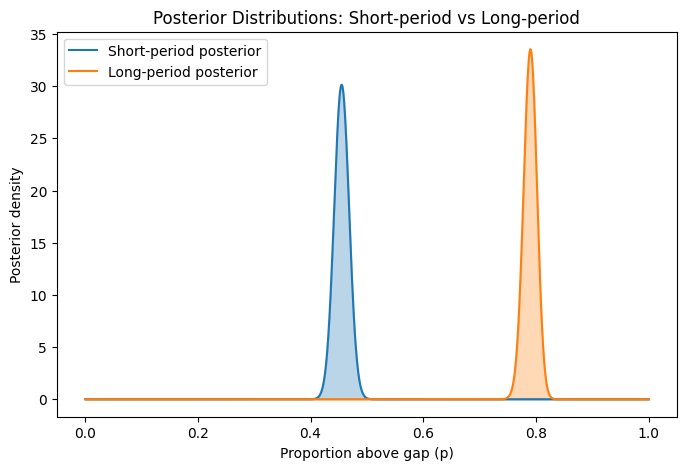

In [5]:
x = np.linspace(0, 1, 1000)

plt.figure(figsize=(8, 5))
plt.plot(x, beta.pdf(x, posterior_a_short, posterior_b_short), label='Short-period posterior', color='#1f77b4')
plt.plot(x, beta.pdf(x, posterior_a_long, posterior_b_long), label='Long-period posterior', color='#ff7f0e')
plt.fill_between(x, beta.pdf(x, posterior_a_short, posterior_b_short), alpha=0.3, color='#1f77b4')
plt.fill_between(x, beta.pdf(x, posterior_a_long, posterior_b_long), alpha=0.3, color='#ff7f0e')
plt.xlabel('Proportion above gap (p)')
plt.ylabel('Posterior density')
plt.title('Posterior Distributions: Short-period vs Long-period')
plt.legend()
plt.show()

In [6]:
np.random.seed(42)
n_samples = 100000

samples_short = beta.rvs(posterior_a_short, posterior_b_short, size=n_samples)
samples_long = beta.rvs(posterior_a_long, posterior_b_long, size=n_samples)

delta = samples_long - samples_short

mean_delta = delta.mean()
ci_delta = np.percentile(delta, [2.5, 97.5])
prob_positive = (delta > 0).mean()

print(f"Mean delta (long - short): {mean_delta:.4f}")
print(f"95% credible interval: [{ci_delta[0]:.4f}, {ci_delta[1]:.4f}]")
print(f"P(p_long > p_short | data) = {prob_positive:.4f}"
      f"   (Monte Carlo estimate from {n_samples:,} draws; report as > 0.9999, not as exactly 1)")

Mean delta (long - short): 0.3345
95% credible interval: [0.2993, 0.3691]
P(p_long > p_short | data) = 1.0000   (Monte Carlo estimate from 100,000 draws; report as > 0.9999, not as exactly 1)


## Posterior difference: Δ = p_long − p_short

Using Monte Carlo simulation (100,000 draws from each posterior), we estimated the posterior distribution of the difference in proportions Δ = p_long − p_short.

- **Mean Δ** = 0.335
- **95% credible interval** = [0.299, 0.369]
- **P(p_long > p_short | data)** > 0.9999

The credible interval excludes zero entirely, and essentially all posterior mass supports p_long > p_short — strong Bayesian evidence for a real difference in proportions.

(P is a Monte Carlo estimate from 100,000 draws; none of them fell below zero, so it is reported as > 0.9999 rather than as exactly 1.)

On interpretation: this establishes that long-period planets in *this sample* are more often above the gap. Attributing that to atmospheric mass loss requires ruling out period-dependent detection bias, which notebook 06 shows this sample cannot do.

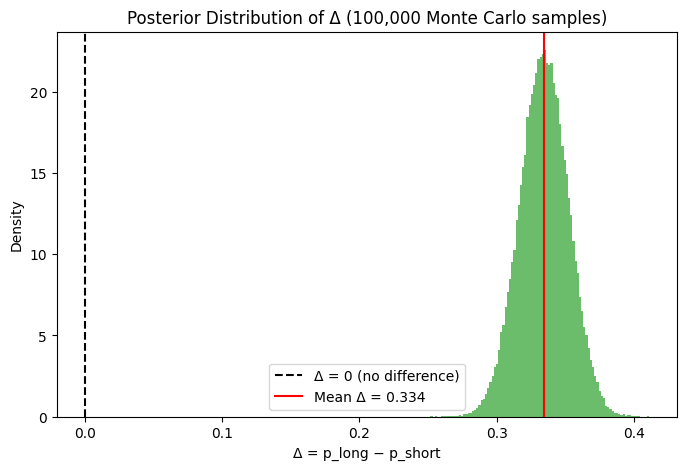

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(delta, bins=100, color='#2ca02c', alpha=0.7, density=True)
plt.axvline(0, color='black', linestyle='--', label='Δ = 0 (no difference)')
plt.axvline(mean_delta, color='red', linestyle='-', label=f'Mean Δ = {mean_delta:.3f}')
plt.xlabel('Δ = p_long − p_short')
plt.ylabel('Density')
plt.title('Posterior Distribution of Δ (100,000 Monte Carlo samples)')
plt.legend()
plt.show()

In [8]:
prior_a1, prior_b1 = 2, 2

posterior_a_short1 = prior_a1 + success_short
posterior_b_short1 = prior_b1 + failures_short

posterior_a_long1 = prior_a1 + success_long
posterior_b_long1 = prior_b1 + failures_long

samples_short1 = beta.rvs(posterior_a_short1, posterior_b_short1, size=n_samples)
samples_long1 = beta.rvs(posterior_a_long1, posterior_b_long1, size=n_samples)

delta1 = samples_long1 - samples_short1

print(f"Alternative prior Beta(2,2):")
print(f"Mean delta: {delta1.mean():.4f}")
print(f"95% CI: [{np.percentile(delta1, 2.5):.4f}, {np.percentile(delta1, 97.5):.4f}]")
print(f"P(p_long > p_short | data) = {(delta1 > 0).mean():.4f}")

Alternative prior Beta(2,2):
Mean delta: 0.3339
95% CI: [0.2985, 0.3685]
P(p_long > p_short | data) = 1.0000


In [9]:
prior_a2, prior_b2 = 20, 20

posterior_a_short2 = prior_a2 + success_short
posterior_b_short2 = prior_b2 + failures_short

posterior_a_long2 = prior_a2 + success_long
posterior_b_long2 = prior_b2 + failures_long

samples_short2 = beta.rvs(posterior_a_short2, posterior_b_short2, size=n_samples)
samples_long2 = beta.rvs(posterior_a_long2, posterior_b_long2, size=n_samples)

delta2 = samples_long2 - samples_short2

print(f"Alternative prior Beta(20,20):")
print(f"Short-period posterior mean: {posterior_a_short2/(posterior_a_short2+posterior_b_short2):.4f}")
print(f"Long-period posterior mean: {posterior_a_long2/(posterior_a_long2+posterior_b_long2):.4f}")
print(f"Mean delta: {delta2.mean():.4f}")
print(f"95% CI: [{np.percentile(delta2, 2.5):.4f}, {np.percentile(delta2, 97.5):.4f}]")
print(f"P(p_long > p_short | data) = {(delta2 > 0).mean():.4f}")

Alternative prior Beta(20,20):
Short-period posterior mean: 0.4564
Long-period posterior mean: 0.7805
Mean delta: 0.3241
95% CI: [0.2893, 0.3585]
P(p_long > p_short | data) = 1.0000


## Prior sensitivity check

We tested three priors of increasing strength to confirm our conclusion doesn't depend on the choice of prior:

- **Beta(1,1)** (uniform, uninformative): mean Δ = 0.335, 95% CI = [0.299, 0.369], P(p_long > p_short) > 0.9999
- **Beta(2,2)** (mild pull toward 0.5): mean Δ = 0.334, 95% CI = [0.299, 0.369], P(p_long > p_short) > 0.9999
- **Beta(20,20)** (strong, "skeptical" pull toward 0.5): mean Δ = 0.324, 95% CI = [0.289, 0.359], P(p_long > p_short) > 0.9999

Even the strongest, actively skeptical prior barely shifts the result (mean Δ moves from 0.335 to 0.324, a difference far smaller than the credible interval width), and the conclusion is unchanged across all three. This confirms the data itself, not the modeling choice, is driving the conclusion.

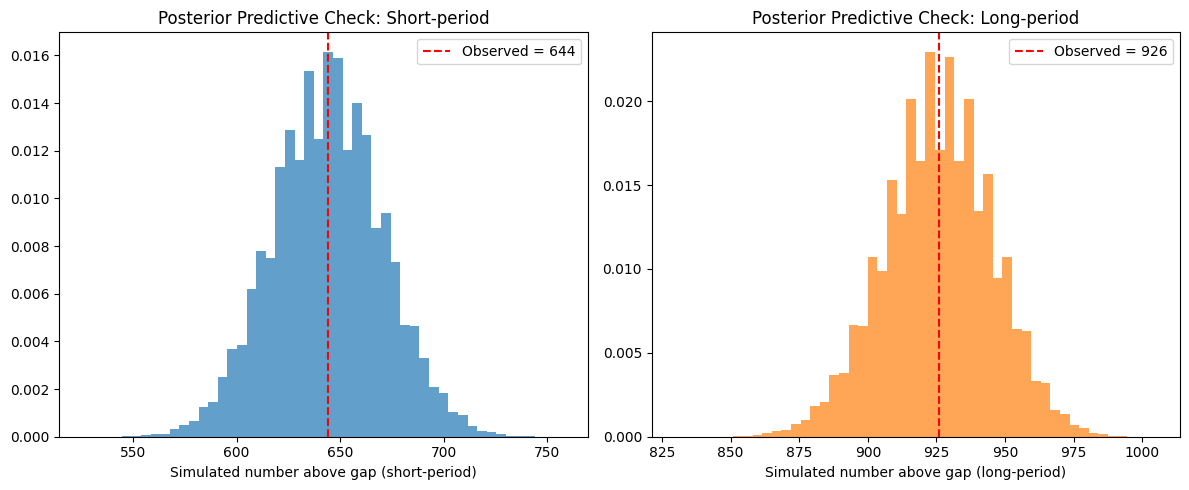

In [10]:
np.random.seed(42)

sim_short = np.random.binomial(n_short, samples_short)
sim_long = np.random.binomial(n_long, samples_long)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(sim_short, bins=50, color='#1f77b4', alpha=0.7, density=True)
plt.axvline(success_short, color='red', linestyle='--', label=f'Observed = {success_short}')
plt.xlabel('Simulated number above gap (short-period)')
plt.title('Posterior Predictive Check: Short-period')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(sim_long, bins=50, color='#ff7f0e', alpha=0.7, density=True)
plt.axvline(success_long, color='red', linestyle='--', label=f'Observed = {success_long}')
plt.xlabel('Simulated number above gap (long-period)')
plt.title('Posterior Predictive Check: Long-period')
plt.legend()

plt.tight_layout()
plt.show()

## Posterior predictive check

To assess model fit, we simulated 100,000 replicated datasets by drawing p from each posterior and generating a hypothetical count of above-gap planets via a Binomial draw, then compared these simulated counts to the actually observed counts.

In both groups, the observed value falls squarely within the bulk of the simulated distribution (644 for short-period, 926 for long-period, both near the peak of their respective histograms). **This check cannot fail, and is therefore weak evidence.** The posterior was fitted to exactly these counts, so replicated counts drawn from it will always centre on them. It verifies the conjugate update was implemented correctly, not that the Binomial likelihood is appropriate.

The assumption that *can* fail here is **independence between planets**: 1,089 of the 2,587 planets share a host system with another sample member, and the peas-in-a-pod effect demonstrated in notebook 01 means their radii are correlated, which could in principle make these intervals too narrow.

Notebook 06 tests this by bootstrapping whole host systems instead of individual planets, and finds the interval widens from [0.299, 0.369] to [0.299, 0.370] — an inflation of 1.02x. Most hosts contribute a single planet to the filtered sample, and multi-planet systems usually straddle both the period cut and the gap, so the clustering largely cancels in a difference of proportions. The assumption is violated in form but not in consequence.

In [11]:
results = []
for threshold in [5, 10, 20]:
    grp = np.where(df['pl_orbper'] <= threshold, 'short', 'long')
    n_s = (grp == 'short').sum()
    succ_s = ((grp == 'short') & (df['above_gap'] == 1)).sum()
    n_l = (grp == 'long').sum()
    succ_l = ((grp == 'long') & (df['above_gap'] == 1)).sum()

    post_a_s, post_b_s = 1 + succ_s, 1 + (n_s - succ_s)
    post_a_l, post_b_l = 1 + succ_l, 1 + (n_l - succ_l)

    samp_s = beta.rvs(post_a_s, post_b_s, size=n_samples)
    samp_l = beta.rvs(post_a_l, post_b_l, size=n_samples)
    d = samp_l - samp_s

    results.append({
        'threshold': threshold,
        'n_short': n_s, 'n_long': n_l,
        'p_short': succ_s/n_s, 'p_long': succ_l/n_l,
        'mean_delta': d.mean(),
        'ci_low': np.percentile(d, 2.5), 'ci_high': np.percentile(d, 97.5),
        'P(delta>0)': (d > 0).mean()
    })

results_df = pd.DataFrame(results)
print(results_df)

   threshold  n_short  n_long   p_short    p_long  mean_delta    ci_low  \
0          5      797    1790  0.319950  0.734637    0.414050  0.375359   
1         10     1415    1172  0.455124  0.790102    0.334445  0.299197   
2         20     2004     583  0.544411  0.821612    0.276136  0.237625   

    ci_high  P(delta>0)  
0  0.451778         1.0  
1  0.369040         1.0  
2  0.313271         1.0  


## Sensitivity to period threshold definition

To confirm the conclusion doesn't depend on the specific 10-day cutoff used to define "short" vs. "long" period, we repeated the full analysis with thresholds of 5, 10, and 20 days.

| Threshold | n_short | n_long | p_short | p_long | Mean Δ | 95% CI | P(Δ>0) |
|---|---|---|---|---|---|---|---|
| 5 days | 797 | 1790 | 0.320 | 0.735 | 0.414 | [0.375, 0.452] | > 0.9999 |
| 10 days | 1415 | 1172 | 0.455 | 0.790 | 0.334 | [0.299, 0.369] | > 0.9999 |
| 20 days | 2004 | 583 | 0.544 | 0.822 | 0.276 | [0.238, 0.313] | > 0.9999 |

Across all three thresholds, P(p_long > p_short | data) > 0.9999 and the credible intervals never come close to including zero. The magnitude of the difference shrinks somewhat as the threshold increases (since the "short" group starts including planets progressively farther from the star), but the direction and statistical certainty of the effect are completely stable — confirming this is a robust finding, not an artifact of one arbitrary threshold choice.

# Phase 8 Summary: Bayesian Beta-Binomial Analysis

This phase used a Bayesian Beta-Binomial model to estimate and compare the proportion of above-gap ("sub-Neptune-like") planets between short-period and long-period planets, with a full suite of robustness checks.

**Posterior estimates** (10-day threshold): short-period proportion = 0.455 (95% CI [0.429, 0.481]); long-period proportion = 0.790 (95% CI [0.766, 0.812]) — non-overlapping, clearly separated posterior distributions.

**Posterior difference**: Δ = p_long − p_short, mean = 0.335, 95% CI [0.299, 0.369], P(p_long > p_short | data) > 0.9999.

**Prior sensitivity**: results were essentially unchanged across three priors of increasing strength (Beta(1,1), Beta(2,2), Beta(20,20)), confirming the conclusion is data-driven, not prior-dependent.

**Posterior predictive check**: replicated counts centre on the observed values, confirming the conjugate update was implemented correctly. This check cannot detect likelihood misfit, since the posterior was conditioned on those same counts. The assumption that could fail — independence between planets sharing a host — is tested separately in notebook 06 via a cluster bootstrap, and turns out to inflate the interval by only 1.02x.

**Threshold sensitivity**: the conclusion held with complete certainty (P(Δ>0) > 0.9999) across period thresholds of 5, 10, and 20 days, though the effect size shrinks somewhat as the threshold widens.

**Overall conclusion**: This Bayesian analysis provides strong, robust and interpretable evidence — fully consistent with the classical tests from Phase 7 — that long-period planets in this sample are substantially more likely to fall above the radius gap than short-period planets. The result is stable across priors, across period thresholds, and under a cluster bootstrap that relaxes the independence assumption.

The physical interpretation is the weaker link: photoevaporation and core-powered mass-loss both predict this pattern, but so does transit detection bias, which removes small long-period planets from the sample. See notebook 06.